# PCA (Principal Component Analysis)

## ¿Cuál es el objetivo de PCA?

El **Análisis de Componentes Principales (PCA)** es un algoritmo de **reducción de dimensionalidad**. Su objetivo es transformar un conjunto de datos con muchas features en uno con menos features, **conservando la mayor cantidad de información posible**.

La idea intuitiva: si tienes datos en 3D pero casi todos los puntos están sobre un plano, PCA encuentra ese plano y proyecta los datos sobre él, reduciendo de 3D a 2D sin perder casi nada de información.

Formalmente, PCA busca las **direcciones de máxima varianza** en los datos. Estas direcciones se llaman **componentes principales** y son los **eigenvectores** de la matriz de covarianza.

$$
\mathbf{X}_{\text{reducido}} = (\mathbf{X} - \boldsymbol{\mu}) \cdot \mathbf{W}^T
$$

Donde:

- $\mathbf{X}$: datos originales ($n \times d$).
- $\boldsymbol{\mu}$: media de cada feature.
- $\mathbf{W}$: matriz de los $k$ eigenvectores principales ($k \times d$).
- $\mathbf{X}_{\text{reducido}}$: datos proyectados ($n \times k$), con $k < d$.

A diferencia de los algoritmos anteriores (KNN, Regresión Logística, Naive Bayes), PCA **no es un algoritmo de clasificación ni de regresión**. Es un método de **aprendizaje no supervisado**: no usa etiquetas $y$, solo trabaja con las features $\mathbf{X}$.

**¿Para qué sirve?**
- **Visualización**: reducir a 2D o 3D para graficar datos de alta dimensionalidad.
- **Preprocesamiento**: reducir el ruido y la redundancia antes de entrenar otro modelo.
- **Compresión**: almacenar datos de forma más eficiente.

**Supongamos un conjunto de datos simples**

Consideremos datos en 2D donde las dos features están correlacionadas:

| $x_1$ | $x_2$ |
|-------|-------|
| 1.0   | 2.1   |
| 2.0   | 3.8   |
| 3.0   | 6.2   |
| 4.0   | 7.9   |
| 5.0   | 10.1  |
| 6.0   | 12.0  |

Los puntos están casi sobre una línea ($x_2 \approx 2 x_1$). Esto significa que la mayor parte de la varianza está en **una sola dirección**, y podríamos representar estos datos con una sola componente principal en lugar de dos.

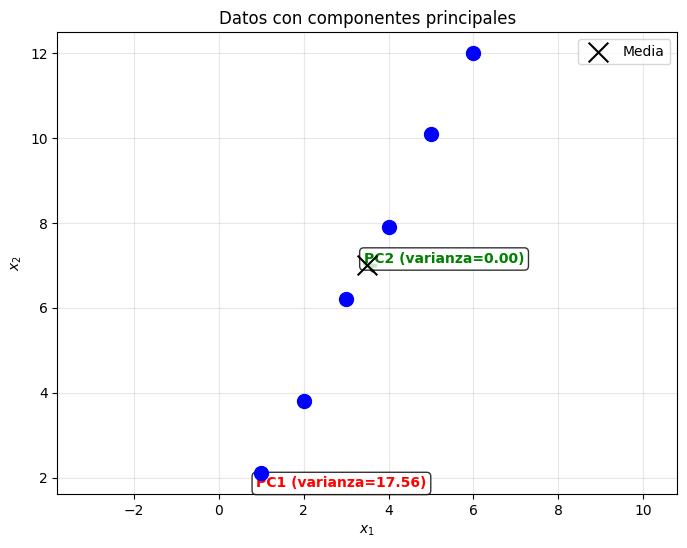

Varianza explicada: PC1 = 100.0%, PC2 = 0.0%


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos correlacionados
X = np.array([[1.0, 2.1], [2.0, 3.8], [3.0, 6.2], [4.0, 7.9], [5.0, 10.1], [6.0, 12.0]])

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], color='blue', s=100, zorder=5)

# Centrar datos
mean = X.mean(axis=0)
X_centered = X - mean

# Calcular eigenvectores
cov = np.cov(X_centered.T)
eigenvalues, eigenvectors = np.linalg.eig(cov)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Dibujar componentes principales desde la media
for i, (eigval, eigvec) in enumerate(zip(eigenvalues, eigenvectors.T)):
    scale = np.sqrt(eigval) * 2
    color = 'red' if i == 0 else 'green'
    label = f'PC{i+1} (varianza={eigval:.2f})'
    plt.annotate('', xy=mean + eigvec * scale, xytext=mean,
                 arrowprops=dict(arrowstyle='->', color=color, lw=3))
    plt.annotate(label, xy=mean + eigvec * scale * 0.7,
                 fontsize=10, color=color, fontweight='bold',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.scatter(*mean, color='black', marker='x', s=200, zorder=5, label='Media')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Datos con componentes principales')
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

var_explained = eigenvalues / eigenvalues.sum() * 100
print(f"Varianza explicada: PC1 = {var_explained[0]:.1f}%, PC2 = {var_explained[1]:.1f}%")

## ¿Cómo encuentra PCA las mejores direcciones?

Cuando miramos los datos del ejemplo anterior, vemos que los puntos se extienden **principalmente en una dirección** (la diagonal). PCA formaliza esta intuición buscando la dirección que **maximiza la varianza** de los datos proyectados.

¿Por qué maximizar la varianza? Porque **varianza = información**. Una dirección con mucha varianza separa bien los datos; una con poca varianza es esencialmente ruido.

La herramienta matemática clave para encontrar estas direcciones es la **descomposición en eigenvectores** de la **matriz de covarianza**.

## Demostración Matemática

### Paso 1: Centrar los datos

El primer paso es **restar la media** de cada feature para que los datos estén centrados en el origen:

$$
\tilde{\mathbf{X}} = \mathbf{X} - \boldsymbol{\mu}
$$

Donde $\boldsymbol{\mu} = \frac{1}{n}\sum_{i=1}^{n} \mathbf{x}_i$ es el vector de medias.

**¿Por qué centrar?** Porque queremos medir la varianza respecto al origen, no respecto a un punto arbitrario. Centrar asegura que la matriz de covarianza refleje correctamente la dispersión de los datos.

### Paso 2: La matriz de covarianza

La **matriz de covarianza** resume cómo varían las features entre sí. Para datos centrados con $n$ muestras y $d$ features:

$$
\mathbf{C} = \frac{1}{n-1} \tilde{\mathbf{X}}^T \tilde{\mathbf{X}}
$$

Esta es una matriz $d \times d$ donde:

- $C_{jj}$: **varianza** de la feature $j$.
- $C_{jk}$: **covarianza** entre las features $j$ y $k$.

Si $C_{jk} > 0$, las features $j$ y $k$ crecen juntas (correlación positiva).  
Si $C_{jk} = 0$, las features son independientes (no correlacionadas).  
Si $C_{jk} < 0$, una crece cuando la otra decrece (correlación negativa).

Para nuestro ejemplo de 2 features:

$$
\mathbf{C} = \begin{pmatrix} \text{var}(x_1) & \text{cov}(x_1, x_2) \\ \text{cov}(x_2, x_1) & \text{var}(x_2) \end{pmatrix}
$$

La matriz de covarianza es siempre **simétrica** y **semidefinida positiva**, lo que garantiza que sus eigenvalores sean no negativos.

### Paso 3: Eigenvectores y eigenvalores

El corazón de PCA es la **descomposición eigen** de la matriz de covarianza. Buscamos vectores $\mathbf{v}$ y escalares $\lambda$ tales que:

$$
\mathbf{C} \mathbf{v} = \lambda \mathbf{v}
$$

Donde:

- $\mathbf{v}$: **eigenvector** (dirección de una componente principal).
- $\lambda$: **eigenvalor** (varianza de los datos en esa dirección).

**¿Por qué los eigenvectores son las direcciones de máxima varianza?**

Queremos encontrar la dirección $\mathbf{v}$ (vector unitario) que maximiza la varianza de los datos proyectados:

$$
\text{Var}_{\text{proyectada}} = \mathbf{v}^T \mathbf{C} \mathbf{v}
$$

Sujeto a la restricción $\|\mathbf{v}\| = 1$. Usando multiplicadores de Lagrange:

$$
\mathscr{L} = \mathbf{v}^T \mathbf{C} \mathbf{v} - \lambda(\mathbf{v}^T \mathbf{v} - 1)
$$

Derivando e igualando a cero:

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{v}} = 2\mathbf{C}\mathbf{v} - 2\lambda\mathbf{v} = 0 \implies \mathbf{C}\mathbf{v} = \lambda\mathbf{v}
$$

¡Esto es exactamente la ecuación eigen! Además, la varianza proyectada en esa dirección es:

$$
\mathbf{v}^T \mathbf{C} \mathbf{v} = \mathbf{v}^T \lambda \mathbf{v} = \lambda
$$

Así que **el eigenvalor $\lambda$ es la varianza en esa dirección**. Para maximizar, elegimos el eigenvector con el **eigenvalor más grande**.

### Paso 4: Seleccionar las $k$ componentes principales

Si tenemos $d$ features, obtenemos $d$ eigenvalores $\lambda_1 \geq \lambda_2 \geq \dots \geq \lambda_d$ con sus eigenvectores correspondientes.

Para reducir a $k$ dimensiones, seleccionamos los $k$ eigenvectores con los **eigenvalores más grandes**:

$$
\mathbf{W} = \begin{pmatrix} \mathbf{v}_1 \\ \mathbf{v}_2 \\ \vdots \\ \mathbf{v}_k \end{pmatrix}
$$

La **varianza explicada** por las $k$ componentes es:

$$
\text{Varianza explicada} = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{d} \lambda_i}
$$

Esto nos dice qué **porcentaje de la información original** conservamos. Un criterio común es elegir $k$ tal que se conserve al menos el **95%** de la varianza.

### Paso 5: Proyectar los datos

Finalmente, proyectamos los datos centrados sobre las $k$ componentes:

$$
\mathbf{X}_{\text{reducido}} = \tilde{\mathbf{X}} \cdot \mathbf{W}^T
$$

Cada fila del resultado es un punto en el nuevo espacio de $k$ dimensiones.

### Resumen del algoritmo

1. **Centrar** los datos: $\tilde{\mathbf{X}} = \mathbf{X} - \boldsymbol{\mu}$
2. Calcular la **matriz de covarianza**: $\mathbf{C} = \frac{1}{n-1} \tilde{\mathbf{X}}^T \tilde{\mathbf{X}}$
3. Calcular **eigenvalores y eigenvectores** de $\mathbf{C}$
4. **Ordenar** eigenvectores por eigenvalor descendente
5. **Seleccionar** los $k$ primeros eigenvectores
6. **Proyectar**: $\mathbf{X}_{\text{reducido}} = \tilde{\mathbf{X}} \cdot \mathbf{W}^T$

### Ejemplo numérico

Apliquemos PCA paso a paso a nuestros datos simples, reduciendo de 2D a 1D.

| $x_1$ | $x_2$ |
|-------|-------|
| 1.0   | 2.1   |
| 2.0   | 3.8   |
| 3.0   | 6.2   |
| 4.0   | 7.9   |
| 5.0   | 10.1  |
| 6.0   | 12.0  |

**Paso 1: Centrar**

$$
\boldsymbol{\mu} = \left(\frac{1+2+3+4+5+6}{6}, \ \frac{2.1+3.8+6.2+7.9+10.1+12.0}{6}\right) = (3.5, \ 7.017)
$$

**Paso 2: Matriz de covarianza**

$$
\mathbf{C} = \begin{pmatrix} 3.5 & 6.947 \\ 6.947 & 14.034 \end{pmatrix}
$$

Notar que $\text{cov}(x_1, x_2) = 6.947 > 0$: las features están fuertemente correlacionadas.

**Paso 3: Eigenvalores y eigenvectores**

Resolviendo $\det(\mathbf{C} - \lambda \mathbf{I}) = 0$:

$$
\lambda_1 \approx 17.44, \quad \lambda_2 \approx 0.09
$$

$$
\mathbf{v}_1 \approx (0.445, \ 0.896), \quad \mathbf{v}_2 \approx (-0.896, \ 0.445)
$$

**Paso 4: Varianza explicada**

$$
\text{PC1} = \frac{17.44}{17.44 + 0.09} = 99.5\%
$$

¡La primera componente captura el **99.5%** de la varianza! Podemos reducir de 2D a 1D con pérdida mínima.

**Paso 5: Proyectar**

$$
\mathbf{X}_{\text{1D}} = \tilde{\mathbf{X}} \cdot \mathbf{v}_1
$$

In [ ]:
import numpy as np

X = np.array([[1.0, 2.1], [2.0, 3.8], [3.0, 6.2], [4.0, 7.9], [5.0, 10.1], [6.0, 12.0]])

print("=== Ejemplo numérico: PCA paso a paso ===")

# Paso 1: Centrar
mean = X.mean(axis=0)
X_centered = X - mean
print(f"\nPaso 1 - Media: μ = {mean}")
print(f"Datos centrados:")
for row in X_centered:
    print(f"  [{row[0]:+.3f}, {row[1]:+.3f}]")

# Paso 2: Matriz de covarianza
cov = np.cov(X_centered.T)
print(f"\nPaso 2 - Matriz de covarianza:")
print(f"  [{cov[0,0]:.3f}  {cov[0,1]:.3f}]")
print(f"  [{cov[1,0]:.3f}  {cov[1,1]:.3f}]")

# Paso 3: Eigenvalores y eigenvectores
eigenvalues, eigenvectors = np.linalg.eig(cov)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print(f"\nPaso 3 - Eigenvalores: λ₁ = {eigenvalues[0]:.4f}, λ₂ = {eigenvalues[1]:.4f}")
print(f"Eigenvectores:")
print(f"  v₁ = ({eigenvectors[0,0]:.4f}, {eigenvectors[1,0]:.4f})")
print(f"  v₂ = ({eigenvectors[0,1]:.4f}, {eigenvectors[1,1]:.4f})")

# Paso 4: Varianza explicada
var_explained = eigenvalues / eigenvalues.sum() * 100
print(f"\nPaso 4 - Varianza explicada: PC1 = {var_explained[0]:.1f}%, PC2 = {var_explained[1]:.1f}%")

# Paso 5: Proyectar a 1D
W = eigenvectors[:, 0].reshape(1, -1)  # solo PC1
X_1d = X_centered @ W.T
print(f"\nPaso 5 - Datos proyectados a 1D:")
for i, (orig, proj) in enumerate(zip(X, X_1d)):
    print(f"  ({orig[0]:.1f}, {orig[1]:.1f}) → {proj[0]:.4f}")

=== Ejemplo numérico: PCA paso a paso ===

Paso 1 - Media: μ = [3.5        7.01666667]
Datos centrados:
  [-2.500, -4.917]
  [-1.500, -3.217]
  [-0.500, -0.817]
  [+0.500, +0.883]
  [+1.500, +3.083]
  [+2.500, +4.983]

Paso 2 - Matriz de covarianza:
  [3.500  7.010]
  [7.010  14.062]

Paso 3 - Eigenvalores: λ₁ = 17.5574, λ₂ = 0.0043
Eigenvectores:
  v₁ = (-0.4463, -0.8949)
  v₂ = (-0.8949, 0.4463)

Paso 4 - Varianza explicada: PC1 = 100.0%, PC2 = 0.0%

Paso 5 - Datos proyectados a 1D:
  (1.0, 2.1) → 5.5156
  (2.0, 3.8) → 3.5480
  (3.0, 6.2) → 0.9540
  (4.0, 7.9) → -1.0136
  (5.0, 10.1) → -3.4287
  (6.0, 12.0) → -5.5753


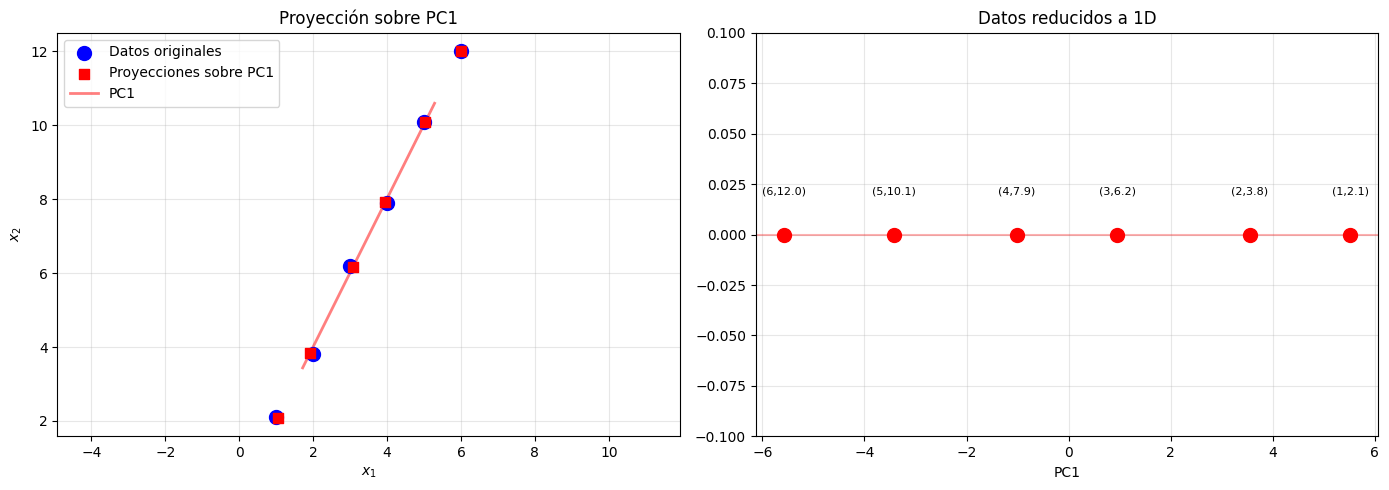

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

X = np.array([[1.0, 2.1], [2.0, 3.8], [3.0, 6.2], [4.0, 7.9], [5.0, 10.1], [6.0, 12.0]])
mean = X.mean(axis=0)
X_centered = X - mean
cov = np.cov(X_centered.T)
eigenvalues, eigenvectors = np.linalg.eig(cov)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Proyecciones sobre PC1
pc1 = eigenvectors[:, 0]
projections = X_centered @ pc1.reshape(-1, 1) * pc1.reshape(1, -1) + mean

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Panel izquierdo: datos originales con proyecciones ---
axes[0].scatter(X[:, 0], X[:, 1], color='blue', s=100, zorder=5, label='Datos originales')
axes[0].scatter(projections[:, 0], projections[:, 1], color='red', s=60, zorder=5, marker='s',
                label='Proyecciones sobre PC1')

# Líneas de proyección
for orig, proj in zip(X, projections):
    axes[0].plot([orig[0], proj[0]], [orig[1], proj[1]], 'k--', alpha=0.3)

# Dibujar PC1
scale = 4
axes[0].plot([mean[0] - pc1[0]*scale, mean[0] + pc1[0]*scale],
             [mean[1] - pc1[1]*scale, mean[1] + pc1[1]*scale],
             'r-', linewidth=2, alpha=0.5, label='PC1')

axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_title('Proyección sobre PC1')
axes[0].axis('equal')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# --- Panel derecho: datos en 1D ---
X_1d = X_centered @ pc1
axes[1].scatter(X_1d, np.zeros_like(X_1d), color='red', s=100, zorder=5)
for i, val in enumerate(X_1d):
    axes[1].annotate(f'({X[i,0]:.0f},{X[i,1]:.1f})', xy=(val, 0),
                     xytext=(val, 0.02), ha='center', fontsize=8)
axes[1].axhline(y=0, color='red', alpha=0.3)
axes[1].set_xlabel('PC1')
axes[1].set_title('Datos reducidos a 1D')
axes[1].set_ylim(-0.1, 0.1)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Implementación con Código

### Funciones

In [ ]:
import numpy as np

def pca_fit(X, n_components):
    """Calcula las componentes principales"""
    # Centrar datos
    mean = np.mean(X, axis=0)
    X_centered = X - mean

    # Matriz de covarianza
    cov = np.cov(X_centered.T)

    # Eigenvalores y eigenvectores
    eigenvalues, eigenvectors = np.linalg.eig(cov)

    # Ordenar por eigenvalor descendente
    eigenvectors = eigenvectors.T
    idxs = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[idxs]
    eigenvectors = eigenvectors[idxs]

    # Seleccionar las k componentes principales
    components = eigenvectors[:n_components]

    return mean, components, eigenvalues

def pca_transform(X, mean, components):
    """Proyecta los datos al espacio reducido"""
    X_centered = X - mean
    return np.dot(X_centered, components.T)

Shape original: (150, 4)
Shape reducido: (150, 2)

Varianza explicada:
  PC1: 92.5%
  PC2: 5.3%
  PC3: 1.7%
  PC4: 0.5%
  Total (2 componentes): 97.8%


/tmp/ipython-input-367/1279433818.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))


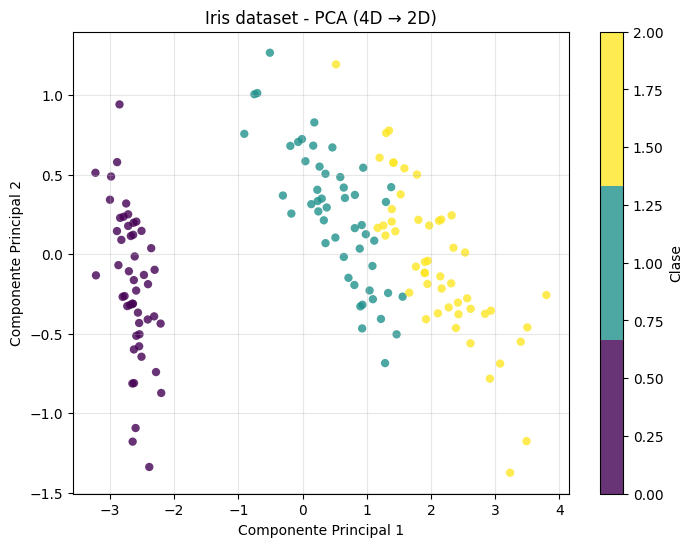

In [ ]:
import matplotlib.pyplot as plt
from sklearn import datasets

# Cargar datos
data = datasets.load_iris()
X = data.data
y = data.target

# Aplicar PCA: de 4D a 2D
mean, components, eigenvalues = pca_fit(X, n_components=2)
X_projected = pca_transform(X, mean, components)

print(f"Shape original: {X.shape}")
print(f"Shape reducido: {X_projected.shape}")

var_explained = eigenvalues / eigenvalues.sum() * 100
print(f"\nVarianza explicada:")
for i, v in enumerate(var_explained):
    print(f"  PC{i+1}: {v:.1f}%")
print(f"  Total (2 componentes): {var_explained[:2].sum():.1f}%")

# Graficar
plt.figure(figsize=(8, 6))
plt.scatter(X_projected[:, 0], X_projected[:, 1], c=y,
            edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Iris dataset - PCA (4D → 2D)')
plt.colorbar(label='Clase')
plt.grid(True, alpha=0.3)
plt.show()

### Clase

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


class PCA:
    def __init__(self, n_components):
        self.n_components = n_components
        self.components = None
        self.mean = None
        self.eigenvalues = None

    def fit(self, X):
        """Calcula las componentes principales"""
        # Centrar datos
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean

        # Matriz de covarianza
        cov = np.cov(X_centered.T)

        # Eigenvalores y eigenvectores
        eigenvalues, eigenvectors = np.linalg.eig(cov)

        # Transponer para que cada fila sea un eigenvector
        eigenvectors = eigenvectors.T

        # Ordenar por eigenvalor descendente
        idxs = np.argsort(eigenvalues)[::-1]
        self.eigenvalues = eigenvalues[idxs]
        eigenvectors = eigenvectors[idxs]

        # Guardar las primeras n componentes
        self.components = eigenvectors[:self.n_components]

    def transform(self, X):
        """Proyecta los datos al espacio reducido"""
        X_centered = X - self.mean
        return np.dot(X_centered, self.components.T)

    def fit_transform(self, X):
        """fit + transform en un solo paso"""
        self.fit(X)
        return self.transform(X)

    def explained_variance_ratio(self):
        """Retorna el porcentaje de varianza explicada por cada componente"""
        return self.eigenvalues / self.eigenvalues.sum()

    def plot_explained_variance(self):
        """Grafica la varianza explicada acumulada"""
        ratios = self.explained_variance_ratio()
        cumulative = np.cumsum(ratios)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # Varianza individual
        axes[0].bar(range(1, len(ratios) + 1), ratios * 100, color='steelblue', alpha=0.7)
        axes[0].set_xlabel('Componente Principal')
        axes[0].set_ylabel('Varianza explicada (%)')
        axes[0].set_title('Varianza explicada por componente')
        axes[0].set_xticks(range(1, len(ratios) + 1))
        axes[0].grid(True, alpha=0.3, axis='y')

        # Varianza acumulada
        axes[1].plot(range(1, len(cumulative) + 1), cumulative * 100, 'bo-', linewidth=2)
        axes[1].axhline(y=95, color='r', linestyle='--', alpha=0.5, label='95% umbral')
        axes[1].set_xlabel('Número de componentes')
        axes[1].set_ylabel('Varianza acumulada (%)')
        axes[1].set_title('Varianza explicada acumulada')
        axes[1].set_xticks(range(1, len(cumulative) + 1))
        axes[1].set_ylim(0, 105)
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    def plot_2d_projection(self, X, y=None, title="Proyección PCA 2D"):
        """Grafica la proyección en 2D (requiere n_components >= 2)"""
        X_proj = self.transform(X)

        plt.figure(figsize=(8, 6))
        if y is not None:
            n_classes = len(np.unique(y))
            scatter = plt.scatter(X_proj[:, 0], X_proj[:, 1], c=y,
                                 edgecolor='none', alpha=0.8,
                                 cmap=plt.cm.get_cmap('viridis', n_classes))
            plt.colorbar(scatter, label='Clase')
        else:
            plt.scatter(X_proj[:, 0], X_proj[:, 1], color='blue',
                        edgecolor='none', alpha=0.8)

        var_ratio = self.explained_variance_ratio()
        plt.xlabel(f'PC1 ({var_ratio[0]*100:.1f}% varianza)')
        plt.ylabel(f'PC2 ({var_ratio[1]*100:.1f}% varianza)')
        plt.title(title)
        plt.grid(True, alpha=0.3)
        plt.show()

Shape original: (150, 4)
Shape reducido: (150, 2)

Varianza explicada por componente:
  PC1: 92.5%
  PC2: 5.3%
  PC3: 1.7%
  PC4: 0.5%


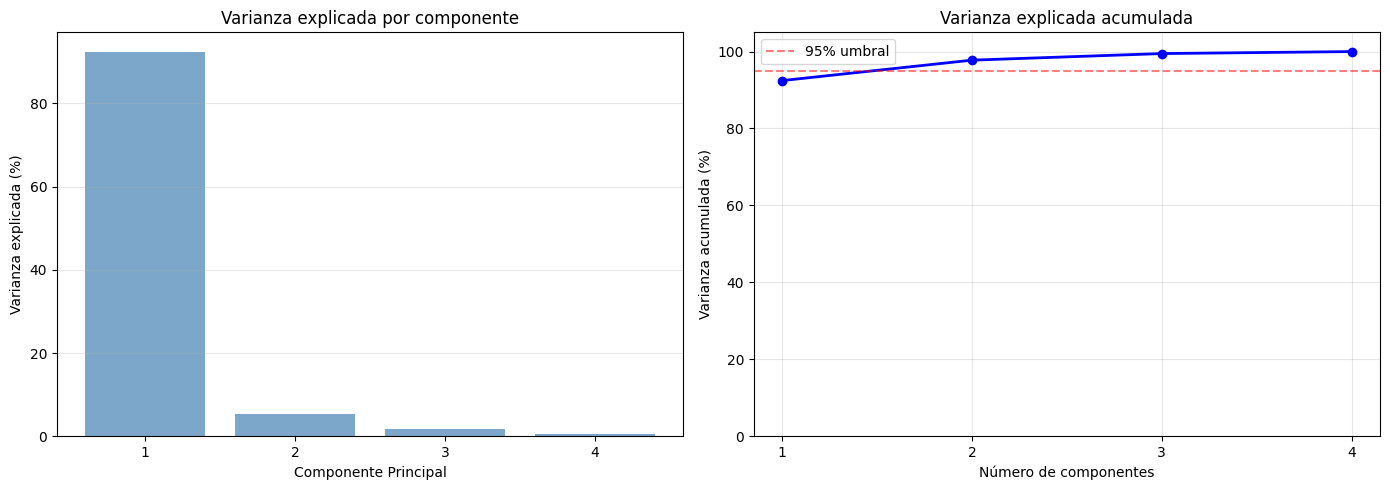

/tmp/ipython-input-367/532346140.py:87: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('viridis', n_classes))


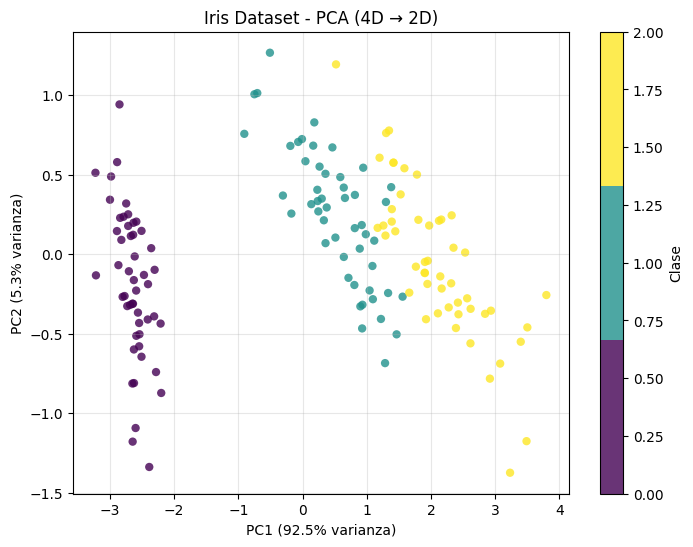

In [ ]:
from sklearn import datasets

# --- Ejemplo con Iris (4D → 2D) ---
data = datasets.load_iris()
X, y = data.data, data.target

print(f"Shape original: {X.shape}")

# Crear y ajustar PCA
pca = PCA(n_components=2)
X_projected = pca.fit_transform(X)

print(f"Shape reducido: {X_projected.shape}")
print(f"\nVarianza explicada por componente:")
for i, ratio in enumerate(pca.explained_variance_ratio()):
    print(f"  PC{i+1}: {ratio*100:.1f}%")

# Visualización
pca.plot_explained_variance()
pca.plot_2d_projection(X, y, title="Iris Dataset - PCA (4D → 2D)")

Shape original: (1797, 64)  (imágenes de 8x8 píxeles aplanadas)


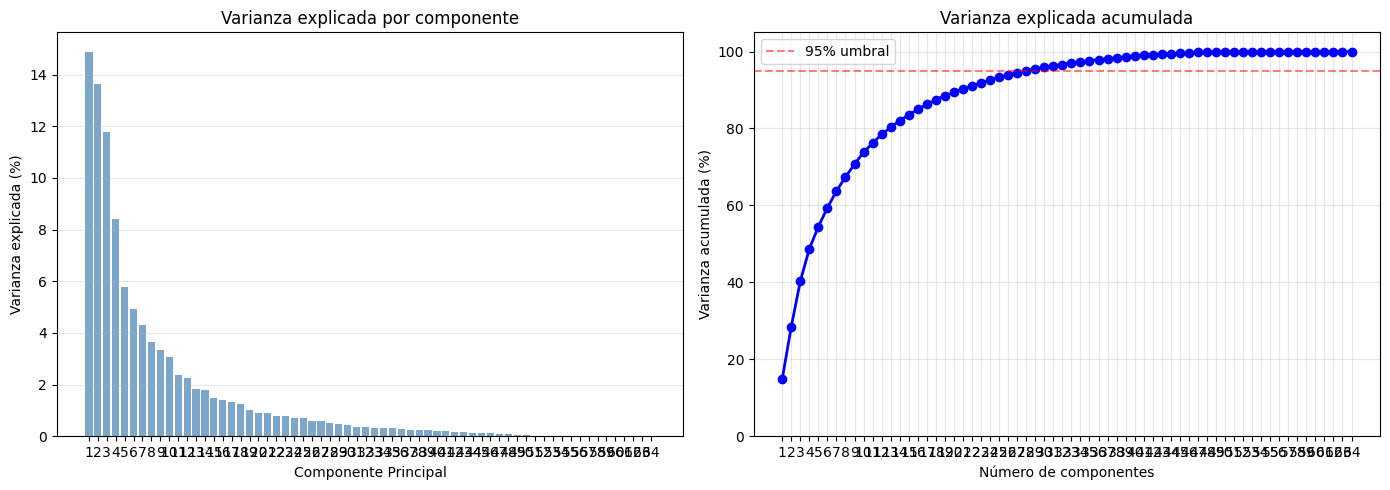


Varianza explicada con 2 componentes: 100.0%
Componentes necesarias para 95% varianza: 29 (de 64)


/tmp/ipython-input-367/532346140.py:87: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('viridis', n_classes))


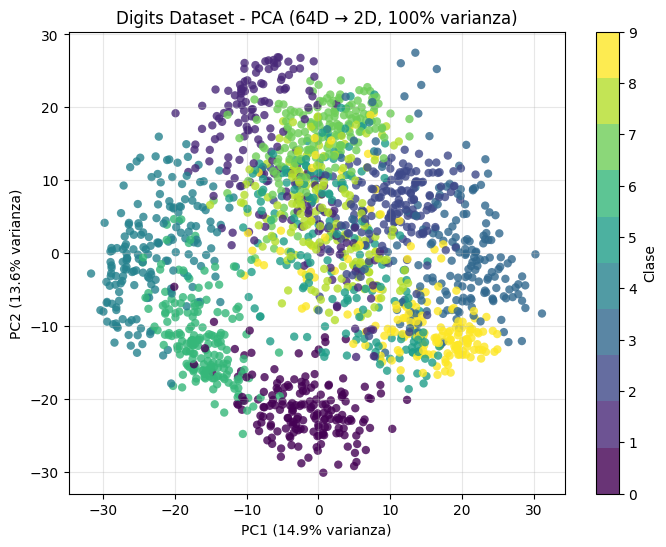

In [ ]:
# --- Ejemplo con Digits (64D → 2D) ---
digits = datasets.load_digits()
X_digits, y_digits = digits.data, digits.target

print(f"Shape original: {X_digits.shape}  (imágenes de 8x8 píxeles aplanadas)")

# PCA con todas las componentes para ver la varianza explicada
pca_full = PCA(n_components=X_digits.shape[1])
pca_full.fit(X_digits)
pca_full.plot_explained_variance()

# PCA reducido a 2D para visualizar
pca_2d = PCA(n_components=2)
pca_2d.fit(X_digits)

var_2 = pca_2d.explained_variance_ratio().sum() * 100
print(f"\nVarianza explicada con 2 componentes: {var_2:.1f}%")

# Buscar cuántas componentes necesitamos para 95%
cumulative = np.cumsum(pca_full.explained_variance_ratio())
n_95 = np.argmax(cumulative >= 0.95) + 1
print(f"Componentes necesarias para 95% varianza: {n_95} (de {X_digits.shape[1]})")

pca_2d.plot_2d_projection(X_digits, y_digits, title=f"Digits Dataset - PCA (64D → 2D, {var_2:.0f}% varianza)")